In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import active_subspaces as ac

SEED = 2022                      # the only seed in this notebook (bootstraps and noise replicates)
NBOOT = 300                      # bootstrap replicates
t_start = time.perf_counter()
m = 8
labels = [f'u{i}' for i in range(1, m + 1)]       # u_i = cos(theta_i), drum i "insertion"

# HOLOS-Quad Microreactor Control Drums: $k_\mathrm{eff}$ and Quadrant Power from Serpent

__Dean Price__, Department of Nuclear Engineering and Radiological Science, University of Michigan, Ann Arbor, MI, United States

__Majdi I. Radaideh__, Department of Nuclear Science and Engineering, Massachusetts Institute of Technology, Cambridge, MA, United States

__Brendan Kochunas__, Department of Nuclear Engineering and Radiological Science, University of Michigan, Ann Arbor, MI, United States

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook analyzes the Serpent runs that Price, Radaideh and Kochunas [[1]][R1] published with their article. The values are **stored data**: they come from a full-core continuous-energy Monte Carlo model that is not public (Serpent is distributed under export control), and they are used here unchanged (`DATA.md`). The paper was read in its accepted-manuscript version (OSTI); page numbers refer to it.

### Summary

Price, Radaideh and Kochunas [[1]][R1] ran 751 Serpent calculations of the 22 MWt HOLOS-Quad gas-cooled microreactor with its eight control drums turned to random angles, and trained a neural network on the four quadrant powers to optimize drum positions. Because the drum angles are periodic, the runs are analyzed here in the drum "insertion" variables $u_i = \cos\theta_i$; in these, a global quadratic (QPHD) gives one dominant direction for $k_\mathrm{eff}$ ($\lambda_1/\lambda_2 = 18.8$), weighting all eight drums nearly equally with the four side drums 19 % heavier, and one for the quadrant-1 power fraction ($\lambda_1/\lambda_2 = 35.7$) that sets the quadrant's own drums against the opposite quadrant's, a pattern that the other three quadrants repeat after the permutation the core symmetry predicts ($|\mathbf w\cdot\mathbf w'| \ge 0.9993$). In the raw angles the same runs show no active subspace (all eight $k_\mathrm{eff}$ eigenvalues within a factor 1.56) and a linear fit explains nothing ($R^2 = 0.01$, as the paper's Table 2), whereas quadratics in one active variable reach leave-one-out $R^2 = 0.949$ ($k_\mathrm{eff}$) and 0.951 ($P_1$), with leading eigenvalues more than 1000 times a conservative Monte Carlo noise floor computed from the stored Serpent uncertainties.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$ [[2]][R2], [[3]][R3]. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$, and a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows its main trend. Without gradients, $\nabla f$ is replaced by the gradient of a model fitted to the values; here a global least-squares quadratic $q(\mathbf x) = c + \mathbf g^T\mathbf x + \tfrac12\mathbf x^T\mathbf H\mathbf x$, for which $\mathbf C = \mathbf g\mathbf g^T + \mathbf H\boldsymbol\Sigma\mathbf H$ with $\boldsymbol\Sigma$ the covariance of the normalized inputs (QPHD, after Li's principal Hessian directions [[4]][R4]). A short introduction is [Constantine (2015)](https://doi.org/10.1137/1.9781611973860) [[2]][R2].

### The model

**Reactor** (Sect. 2.1, p. 5, Fig. 1). HOLOS-Quad is a 22 MWt high-temperature gas-cooled microreactor built from four transportable subcritical modules (the four core quadrants). TRISO fuel sits in hexagonal graphite blocks cooled by helium, inside a BeO reflector of radius about 1 m. Eight cylindrical control drums, two per quadrant, carry a B$_4$C absorber on part of their surface and control reactivity by rotating it towards or away from the fuel (Sect. 2.1, p. 6). Each drum can rotate a full 360° (Sect. 2.2, p. 6).

**Simulator** (Sect. 2.3, p. 7). For each configuration of the eight drum angles $\boldsymbol\theta = (\theta_1, \dots, \theta_8)$, a continuous-energy Monte Carlo neutron transport model in **Serpent** [[5]][R5] (TRISO particles modelled explicitly, p. 6) computes $k_\mathrm{eff}$ and the neutron flux tallied in each of the four quadrants. The paper's Eq. (1) defines the quadrant power tilt ratio
$$\mathrm{QPTR} = \frac{4\max(P_1, P_2, P_3, P_4)}{P_1 + P_2 + P_3 + P_4},$$
"where $P_i$ indicates the flux in the $i$-th core quadrant" (p. 7); the neural network of Eq. (2) predicts "relative quadrant power" (p. 14), i.e. the four fluxes scaled to sum to one. (The pyMAISE documentation of the same data [[6]][R6] says MCNP; the paper says Serpent.) The Serpent version, neutron population and reactor state (temperatures, burnup) are not given.

**Quantities of interest.** (i) $k_\mathrm{eff}$ (stored column `k`); (ii) the relative quadrant power $P_q = \phi_q / \sum_{j=1}^4 \phi_j$, $q = 1, \dots, 4$, from the flux tallies $\phi_q$ (`fluxQ1`–`fluxQ4`); $P_1$ is analysed in full and $P_2$–$P_4$ for the symmetry. QPTR is a maximum (not smooth) and is only summarized.

**Inputs** (m = 8). "Each angle was selected from a uniform random distribution spanning −180° to 180°" (p. 7), independently. In the paper's local angle, 0° is "the drum position where the absorbing material is fully facing the core" and $|\theta|$ "is indicative of how withdrawn the absorbing material is" (p. 17). The stored columns hold Serpent's global orientations in radians; the authors' conversion (`g2l` in their repository, zero points and rotation signs per drum) is applied once, in the cell after loading. Quadrants are numbered counterclockwise from the top right, and drums counterclockwise from the lower drum of quadrant 1 (authors' README), so drums 1, 4, 5, 8 face the core from the left and right sides and drums 2, 3, 6, 7 from the top and bottom (Fig. 1).

**Periodic inputs and the analysis variables.** The inputs live on a torus: $-180°$ and $180°$ are the same drum position, and every output is $2\pi$-periodic in each angle. Treating the angles as a box loses this. Worse, the dominant drum effect is close to $\sum_i c_i\cos\theta_i$, whose gradient $(-c_i\sin\theta_i)_i$ has $\mathbf C = \mathrm{diag}(c_i^2)/2$ under uniform angles: diagonal, with no low-dimensional structure, even though $k_\mathrm{eff}$ is then a function of one linear combination of the $\cos\theta_i$. The analysis therefore uses the insertion variables
$$u_i = \cos\theta_i \in [-1, 1],\qquad u_i = 1:\ \text{absorber facing the core},\quad u_i = -1:\ \text{turned fully away}.$$
With $\theta_i$ uniform, the $u_i$ are independent with the arcsine density $1/(\pi\sqrt{1-u^2})$, mean 0 and variance 1/2. The library has no arcsine input space. QPHD's $\mathbf C = \mathbf g\mathbf g^T + \mathbf H\boldsymbol\Sigma\mathbf H$ is the average of $\nabla q\,\nabla q^T$ for the fitted quadratic $q$, and for a quadratic that average depends on the input density only through its mean and covariance (the least-squares fit itself does not use the space at all). The space is therefore declared as `ac.Gaussian(0, 0.5 I)`, which has exactly the mean and covariance of the arcsine law the $u_i$ follow, so $\mathbf C$ is the average over the actual sampling distribution, and every input is scaled the same way ($x_i = u_i/\sqrt{1/2}$). The Gaussian is a device for the two moments only: the samples are not Gaussian (they pile up near $u_i = \pm 1$), Stein's lemma (the justification of pHd for Gaussian inputs) does not apply, and `space` must not be used to sample or integrate, since its support is unbounded while $u_i \in [-1, 1]$. Declaring $u$ uniform on $[-1, 1]$ instead would be wrong for these data: its variance is 1/3, not 1/2, so it underweights the curvature term $\mathbf H\boldsymbol\Sigma\mathbf H$ and inflates the leading gap; the $P_1$ estimation cell below prints the size of this effect (the directions do not change).

**What is estimated.** Because the estimator fits a quadratic in $u$, it estimates the active subspace of the best quadratic approximation in $u$, i.e. of the part of $f$ that depends on $u$ only (the part even in every $\theta_i$), and $\mathbf C$ is the average outer product of that quadratic's gradient. It is not the active subspace of $f$ itself as a function of $u$: whenever $f$ has a part odd in some $\theta_i$, $\partial f/\partial u_i = -(\partial f/\partial\theta_i)/\sin\theta_i$ is unbounded at $u_i = \pm 1$, where the arcsine density concentrates. Using $u_i$ drops the sign of $\theta_i$, i.e. which way a drum was turned; the naive-analysis cell below measures what this costs with a full second-order Fourier basis. A 16-variable embedding $(\cos\theta_i, \sin\theta_i)$ is not used for QPHD, because $\cos^2\theta_i + \sin^2\theta_i = 1$ makes its quadratic design rank-deficient.

**Gradients:** none; Monte Carlo tallies have no derivatives and finite differences would be swamped by noise. QPHD needs $(m+1)(m+2)/2 = 45$ runs; there are 751 ($\ge 2 \times 45$).

The table is printed from the conversion constants in the next cell.

In [2]:
# Zero points and rotation signs of the authors' local drum angles: MicroControl pmdata/utils.py, g2l (MIT licence)
OFFSET = np.array([3.6820187359906447, 4.067668586955522, 2.2155167202240653 - np.pi, 2.6011665711889425 - np.pi,
                   0.5404260824008517, 0.9260759333657285, 5.3571093738138575 - np.pi, 5.742759224778734 - np.pi])
SIGN = np.array([1, 1, -1, -1, -1, -1, 1, 1])          # g2l reverses theta3..theta6
QUAD = [1, 1, 2, 2, 3, 3, 4, 4]
print(f"{'input':6s} {'drum':>4s} {'quadrant':>8s} {'stored column':>14s} {'units':>6s} {'range in the study':>20s} {'analysis variable':>18s}")
for i in range(m):
    print(f"{'theta' + str(i + 1):6s} {i + 1:4d} {QUAD[i]:8d} {'theta' + str(i + 1):>14s} {'deg':>6s} {'U[-180, 180)':>20s} {'u' + str(i + 1) + ' = cos theta' + str(i + 1):>18s}")

input  drum quadrant  stored column  units   range in the study  analysis variable
theta1    1        1         theta1    deg         U[-180, 180)    u1 = cos theta1
theta2    2        1         theta2    deg         U[-180, 180)    u2 = cos theta2
theta3    3        2         theta3    deg         U[-180, 180)    u3 = cos theta3
theta4    4        2         theta4    deg         U[-180, 180)    u4 = cos theta4
theta5    5        3         theta5    deg         U[-180, 180)    u5 = cos theta5
theta6    6        3         theta6    deg         U[-180, 180)    u6 = cos theta6
theta7    7        4         theta7    deg         U[-180, 180)    u7 = cos theta7
theta8    8        4         theta8    deg         U[-180, 180)    u8 = cos theta8


### Load data

`microreactor_runs.csv` is the authors' file `pmdata/qpower_full.csv` from their repository, converted losslessly (two `#` header lines; the run label `sample_00012` written as 12; every number kept as its original text; `convert_data.py`). The pyMAISE copy of the same runs on Zenodo (CC BY 4.0) rounds the flux columns to three significant digits (a step of about 0.4 % of a flux, more than the Monte Carlo error) and is therefore not used; `DATA.md` documents the check that the two are the same runs. No row is dropped.

In [3]:
A = np.loadtxt('microreactor_runs.csv', delimiter=',')   # 751 x 37, physical units as stored
run = A[:, 0].astype(int)                 # run number (label sample_NNNNN)
k = A[:, 1]                               # k_eff
k_rsd = A[:, 2]                           # its relative standard deviation (Serpent)
flux = A[:, 5:9]                          # quadrant flux tallies Q1..Q4 (n/cm^2/s)
fissE = A[:, 13:17]                       # quadrant fission-energy tallies Q1..Q4
flux_rsd = A[:, 17:21]                    # relative standard deviations of the flux tallies
fissE_rsd = A[:, 25:29]
theta_glob = A[:, 29:37]                  # drum angles, rad, Serpent global orientation
print('runs', A.shape, '| k', k.shape, '| flux', flux.shape, '| angles', theta_glob.shape)

runs (751, 37) | k (751,) | flux (751, 4) | angles (751, 8)


**Inputs and checks of the design.** The cell converts the stored global angles to the paper's local angles in degrees (the authors' `g2l`) and then to $u_i = \cos\theta_i$; it checks the range, uniformity and independence of the angles, and counts the run numbers.

In [4]:
# The one conversion of the inputs: global orientation (rad) -> the paper's local angle (deg) -> u = cos(theta)
loc = ((theta_glob - OFFSET + 2 * np.pi) * SIGN) % (2 * np.pi)
loc = np.where(loc > np.pi, loc - 2 * np.pi, loc)       # (-pi, pi]; 0 = absorber facing the core
theta = np.degrees(loc)                                   # deg, as in the paper
U = np.cos(loc)                                           # analysis inputs, in [-1, 1]
Vs = np.sin(loc)
P = flux / flux.sum(axis=1, keepdims=True)                # relative quadrant power (flux fraction), as the paper
M = len(k)
print('local angles (deg): min', np.array2string(theta.min(0), precision=1), '\n                    max', np.array2string(theta.max(0), precision=1))
ks = [stats.kstest((theta[:, i] + 180) / 360, 'uniform').pvalue for i in range(m)]
print('KS test against U[-180, 180), p-values:', np.array2string(np.array(ks), precision=2))
R = np.corrcoef(theta.T); print(f'largest |correlation| between two angles: {np.abs(R - np.eye(m)).max():.3f} (M = {M}; 2/sqrt(M) = {2 / np.sqrt(M):.3f})')
print(f'u = cos(theta): mean {U.mean():+.3f}, per-drum variance {U.var(0).min():.3f}..{U.var(0).max():.3f} (arcsine law: 0, 0.5)')
missing = np.setdiff1d(np.arange(run.max() + 1), run)
print(f'run numbers {run.min()}..{run.max()}: {len(run)} present, {len(missing)} absent')

local angles (deg): min [-178.9 -179.9 -178.7 -179.9 -179.5 -179.3 -180.  -179.7] 
                    max [179.5 179.8 179.4 179.2 179.9 179.9 179.7 177.8]
KS test against U[-180, 180), p-values: [0.97 0.32 0.6  0.33 0.72 0.69 0.95 0.98]
largest |correlation| between two angles: 0.069 (M = 751; 2/sqrt(M) = 0.073)
u = cos(theta): mean -0.002, per-drum variance 0.479..0.533 (arcsine law: 0, 0.5)
run numbers 0..818: 751 present, 68 absent


The local angles fill the whole circle: every drum spans $[-180°, 180°]$ to within 2.2°, the Kolmogorov–Smirnov tests do not reject uniformity (smallest p-value 0.32), and the largest correlation between two angles, 0.069, is below the $2/\sqrt{M} = 0.073$ expected from chance. The design is therefore independent uniform Monte Carlo sampling on the torus, as the paper says, and the $u_i$ have the arcsine law's moments (mean −0.002, variances 0.479–0.533 against 0.5). The run numbers go from 0 to 818 with 68 missing; the data do not say why (failed or unfinished Serpent runs are a guess), so the 751 runs are taken as they are.

**The outputs and their Monte Carlo noise.** Serpent's relative standard deviations are stored with each run. The cell summarizes them, QPTR, and the fission-energy tallies.

In [5]:
print(f'k_eff: {k.min():.5f} .. {k.max():.5f}, mean {k.mean():.5f}, sd {k.std():.5f}; Serpent sd {np.mean(k_rsd * k):.2e} (mean)')
print(f'flux fractions P_q: sd {np.array2string(P.std(0), precision=5)}; total flux relative sd {flux.sum(1).std() / flux.sum(1).mean():.4f}')
print(f'flux tallies: Serpent relative sd {flux_rsd.min():.5f} .. {flux_rsd.max():.5f} (mean {flux_rsd.mean():.5f})')
QPTR = 4 * P.max(axis=1)                                 # Eq. (1)
print(f'QPTR: {QPTR.min():.4f} .. {QPTR.max():.4f}; {np.sum(QPTR > 1.02)} of {M} runs above the 1.02 limit')
# fission-energy tallies: do they see the drums?
PE = fissE / fissE.sum(axis=1, keepdims=True)
def r2_lin(F, y):
    B = np.column_stack([np.ones(len(y)), F]); c, *_ = np.linalg.lstsq(B, y, rcond=None)
    return 1 - np.sum((y - B @ c)**2) / np.sum((y - y.mean())**2)
print('fission-energy fractions: sd', np.array2string(PE.std(0), precision=6),
      '| R^2 of a linear fit in (cos, sin) of the 8 angles:', np.array2string(np.array([r2_lin(np.column_stack([U, Vs]), PE[:, q]) for q in range(4)]), precision=3),
      '| corr with flux fraction:', np.array2string(np.array([np.corrcoef(PE[:, q], P[:, q])[0, 1] for q in range(4)]), precision=3))

k_eff: 0.97519 .. 1.00563, mean 0.98927, sd 0.00586; Serpent sd 2.41e-04 (mean)
flux fractions P_q: sd [0.00408 0.00426 0.00427 0.00418]; total flux relative sd 0.0091
flux tallies: Serpent relative sd 0.00100 .. 0.00214 (mean 0.00145)
QPTR: 1.0021 .. 1.0611; 388 of 751 runs above the 1.02 limit
fission-energy fractions: sd [0.00018  0.000186 0.000189 0.000184] | R^2 of a linear fit in (cos, sin) of the 8 angles: [0.038 0.018 0.032 0.019] | corr with flux fraction: [ 0.084 -0.001  0.1    0.049]


$k_\mathrm{eff}$ ranges from 0.97519 to 1.00563 (sd 0.00586) with a Serpent standard deviation of 2.41e-4 (24 pcm), so the Monte Carlo noise is 4 % of the spread in sd. The flux fractions vary by about 0.0042 (sd) around 0.25, and the flux tallies carry relative errors of 0.100–0.214 %. QPTR ranges from 1.0021 to 1.0611, and 388 of the 751 random configurations exceed the 1.02 limit the paper quotes (p. 7), which is why drum positions must be optimized. The authors' file also holds quadrant fission-energy tallies (`fissEQ1`–`fissEQ4`); their fractions vary by 1.8e-4 (sd), about their own Monte Carlo error, are uncorrelated with the flux fractions (|r| ≤ 0.1) and are not explained by the drum angles ($R^2 \le 0.038$), so they do not resolve the quadrant power and are not used (a question for the authors). The stored uncertainties are taken as one standard deviation, Serpent's convention, and the tallies' errors as independent; a note in the authors' repository suggests they may be two standard deviations, which would halve the noise used below. The noise levels used below are therefore upper bounds (for $P_1$ the data confirm this in the surrogate section).

**The symmetry the authors used.** To quadruple their training set, the authors map each run to three images (`mult_sym` in their repository): a mirror that swaps quadrants 1↔2 and 3↔4 (`h`), a 180° rotation (`r`) and a mirror that swaps quadrants 1↔4 and 2↔3 (`v`), each permuting the drums and the quadrant tallies. The cell applies their maps to the stored angles and compares the images, in local angles, with permutations of the original local angles.

In [6]:
# The authors' symmetry images (MicroControl utils.mult_sym), applied to the global angles, then mapped to local angles
DRUM = {'h': np.array([3, 2, 1, 0, 7, 6, 5, 4]), 'r': np.array([4, 5, 6, 7, 0, 1, 2, 3]), 'v': np.array([7, 6, 5, 4, 3, 2, 1, 0])}
QMAP = {'h': np.array([1, 0, 3, 2]), 'r': np.array([2, 3, 0, 1]), 'v': np.array([3, 2, 1, 0])}   # image quadrant of Q1..Q4
OP = {'h': lambda t: 3 * np.pi - t, 'r': lambda t: np.pi + t, 'v': lambda t: 2 * np.pi - t}
def to_local(t):
    l = ((t - OFFSET + 2 * np.pi) * SIGN) % (2 * np.pi)
    return np.where(l > np.pi, l - 2 * np.pi, l)
for g in 'hrv':
    img = np.empty_like(theta_glob); img[:, DRUM[g]] = theta_glob; img = OP[g](img) % (2 * np.pi)
    perm = np.empty_like(loc); perm[:, DRUM[g]] = loc
    dev_same = np.degrees(np.abs(np.angle(np.exp(1j * (to_local(img) - perm))))).max()
    dev_flip = np.degrees(np.abs(np.angle(np.exp(1j * (to_local(img) + perm))))).max()
    print(f'{g}: drums {DRUM[g] + 1} <- 1..8, Q1..Q4 -> Q{QMAP[g] + 1}; max deviation from a permutation of the local angles: '
          f'{dev_same:.1e} deg (same sign), {dev_flip:.1e} deg (sign reversed)')

h: drums [4 3 2 1 8 7 6 5] <- 1..8, Q1..Q4 -> Q[2 1 4 3]; max deviation from a permutation of the local angles: 1.5e-13 deg (same sign), 1.8e+02 deg (sign reversed)
r: drums [5 6 7 8 1 2 3 4] <- 1..8, Q1..Q4 -> Q[3 4 1 2]; max deviation from a permutation of the local angles: 1.8e+02 deg (same sign), 2.0e-13 deg (sign reversed)
v: drums [8 7 6 5 4 3 2 1] <- 1..8, Q1..Q4 -> Q[4 3 2 1]; max deviation from a permutation of the local angles: 1.8e+02 deg (same sign), 1.3e-13 deg (sign reversed)


In the local angles the mirror `h` is a pure permutation of the drums, and `r` and `v` are permutations with the sign of every angle reversed (deviations of 1e-13 degrees, i.e. rounding). The sign reversal reflects the authors' rotation conventions (the README's direction rule and `g2l` disagree for quadrants 3 and 4; `DATA.md`). Since $\cos(-\theta) = \cos\theta$, **in the insertion variables $u$ all three symmetries are pure permutations of the drums**: $k_\mathrm{eff}(u)$ is unchanged by them, and $P_{g(q)}(u) = P_q(\Pi_g u)$. Two consequences can be tested: the $k_\mathrm{eff}$ direction must weight the drums equally within each orbit, $\{1, 4, 5, 8\}$ (side drums) and $\{2, 3, 6, 7\}$ (top and bottom drums), and the directions of the four quadrant powers must be permutations of one another.

### Why not the angles themselves

First the naive analysis: QPHD on the local angles as a box $[-180°, 180°]^8$ (uniform), and least-squares fits of $k_\mathrm{eff}$ and $P_1$ in several sets of features.

In [7]:
space_theta = ac.Uniform(-180 * np.ones(m), 180 * np.ones(m), names=[f'theta{i}' for i in range(1, m + 1)])
with warnings.catch_warnings():
    warnings.simplefilter('ignore')                      # ValidityWarning: QPHD on a uniform space (see text)
    naive_k = ac.active_subspace(space=space_theta, X=theta, f=k, estimator='qphd')
    naive_P = ac.active_subspace(space=space_theta, X=theta, f=P[:, 0], estimator='qphd')
for name, s in (('k_eff', naive_k), ('P1', naive_P)):
    lam_ = s.eigenvalues
    print(f'{name}, angles as a box: lambda_1/lambda_8 = {lam_[0] / lam_[-1]:.2f}; ratios', np.array2string(lam_[:-1] / lam_[1:], precision=2))
print('naive P1 w1, w2:', np.array2string(naive_P.W[:, 0], precision=2), np.array2string(naive_P.W[:, 1], precision=2))

def quad_cols(F):
    i, j = np.triu_indices(F.shape[1])
    return np.column_stack([F, F[:, i] * F[:, j]])
feats = {'linear in theta': theta, 'linear in cos': U, 'linear in cos, sin': np.column_stack([U, Vs]),
         'linear in cos, sin, cos 2theta, sin 2theta': np.column_stack([U, Vs, np.cos(2 * loc), np.sin(2 * loc)]),
         'quadratic in cos': quad_cols(U), 'quadratic in cos + linear in sin': np.column_stack([quad_cols(U), Vs])}
print(f"\n{'least-squares fit (in-sample R^2)':45s} {'k_eff':>7s} {'P1':>7s} {'terms':>6s}")
R2 = {}
for name, F in feats.items():
    R2[name] = (r2_lin(F, k), r2_lin(F, P[:, 0]))
    print(f'{name:45s} {R2[name][0]:7.4f} {R2[name][1]:7.4f} {F.shape[1] + 1:6d}')

# What dropping the sign of theta costs: a full second-order Fourier basis, split into the part that depends on u only
# (even in every theta_i: 1, cos theta_i, cos 2theta_i, cos theta_i cos theta_j = the full quadratic in u) and the odd part
# (sin theta_i, sin 2theta_i, cos theta_i sin theta_j, sin theta_i sin theta_j)
from itertools import combinations
pairs = list(combinations(range(m), 2))
EVEN = np.column_stack([np.ones(M), U, np.cos(2 * loc)] + [U[:, i] * U[:, j] for i, j in pairs])
ODD = np.column_stack([Vs, np.sin(2 * loc)] + [U[:, i] * Vs[:, j] for i in range(m) for j in range(m) if i != j]
                      + [Vs[:, i] * Vs[:, j] for i, j in pairs])
FULL = np.column_stack([EVEN, ODD])
def fit_loo(B, f):
    """Least-squares fit in the columns of B: coefficients, leave-one-out residuals (hat matrix), leverages."""
    Q, _ = np.linalg.qr(B); h = np.sum(Q**2, axis=1)
    c, *_ = np.linalg.lstsq(B, f, rcond=None)
    return c, (f - B @ c) / (1 - h), h
print(f'\nFourier basis: {EVEN.shape[1]} terms in u only + {ODD.shape[1]} odd terms = {FULL.shape[1]}')
print(f"{'QoI':6s} {'LOO R^2 u only':>15s} {'LOO R^2 full':>13s} {'gain':>7s} {'var(odd part)/var(f)':>21s} {'LOO RMSE full':>14s}")
odd_share, loo_rmse_full = {}, {}
for name, f in (('k_eff', k), ('P1', P[:, 0]), ('P2', P[:, 1]), ('P3', P[:, 2]), ('P4', P[:, 3])):
    sst = np.sum((f - f.mean())**2)
    _, e_even, _ = fit_loo(EVEN, f)
    c_full, e_f, h_full = fit_loo(FULL, f)
    odd_share[name] = np.var(ODD @ c_full[EVEN.shape[1]:]) / np.var(f)
    loo_rmse_full[name] = np.sqrt(np.mean(e_f**2))
    r2e, r2f = 1 - np.sum(e_even**2) / sst, 1 - np.sum(e_f**2) / sst
    print(f'{name:6s} {r2e:15.4f} {r2f:13.4f} {r2f - r2e:7.4f} {odd_share[name]:21.4f} {loo_rmse_full[name]:14.2e}')

k_eff, angles as a box: lambda_1/lambda_8 = 1.56; ratios [1.04 1.03 1.06 1.15 1.11 1.03 1.03]
P1, angles as a box: lambda_1/lambda_8 = 50.85; ratios [1.14 2.87 1.32 2.39 1.17 3.04 1.38]
naive P1 w1, w2: [ 7.28e-01 -6.85e-01 -2.89e-03 -8.76e-03 -4.23e-03 -9.26e-03 -6.97e-04
  1.93e-02] [ 0.69  0.73 -0.01 -0.    0.    0.    0.   -0.  ]

least-squares fit (in-sample R^2)               k_eff      P1  terms
linear in theta                                0.0135  0.0110      9
linear in cos                                  0.9492  0.9417      9
linear in cos, sin                             0.9547  0.9603     17
linear in cos, sin, cos 2theta, sin 2theta     0.9655  0.9682     33
quadratic in cos                               0.9854  0.9683     45
quadratic in cos + linear in sin               0.9897  0.9871     53

Fourier basis: 45 terms in u only + 100 odd terms = 145
QoI     LOO R^2 u only  LOO R^2 full    gain  var(odd part)/var(f)  LOO RMSE full
k_eff           0.9834        0.9950  0.0

P4              0.9622        0.9957  0.0335                0.0328       2.74e-04


In the angle box the eight $k_\mathrm{eff}$ eigenvalues lie within a factor of 1.56 of each other: no active subspace. For $P_1$ the two leading eigenvalues are nearly equal (ratio 1.14) and their eigenvectors are rotations within the plane of drums 1 and 2, i.e. the box only says "the two drums of quadrant 1 matter"; it finds coordinate directions, not ridges. A linear fit in the angles explains 1.35 % of the variance of $k_\mathrm{eff}$ and 1.10 % of $P_1$, while the same number of terms in $\cos\theta_i$ explains 94.92 % and 94.17 %. Adding the eight $\sin\theta_i$ (the turning direction) gains 0.0055 in in-sample $R^2$ for $k_\mathrm{eff}$ and 0.0186 for $P_1$, and a full quadratic in $u$ reaches 0.9854 and 0.9683. The linear $\sin\theta_i$ terms understate the odd part, so the last table fits a full second-order Fourier basis: 45 terms that depend on $u$ only (the full quadratic in $u$, since $\cos 2\theta_i = 2u_i^2 - 1$) plus 100 odd terms. The odd terms raise the leave-one-out $R^2$ by 0.0116 for $k_\mathrm{eff}$ (0.9834 to 0.9950) and by 0.0312 for $P_1$ (0.9642 to 0.9954; 0.0307–0.0335 for $P_2$–$P_4$), and in the full fit the odd part carries 1.2 % of the variance of $k_\mathrm{eff}$ (0.0120) and about 3 % of the quadrant powers' (0.0306 for $P_1$, 0.0298–0.0328 for $P_2$–$P_4$). So $u$ carries all but about 1 % of $k_\mathrm{eff}$ and all but about 3 % of the quadrant powers; the remainder depends on which way the drums turned, and the analysis below does not see it.

### Estimate the subspace: $k_\mathrm{eff}$

QPHD on the 751 raw runs in $u$, with the moment-matched space described above, 300 bootstrap replicates (seed 2022) and eigenvector signs set so that $k_\mathrm{eff}$ increases along each $\mathbf w_i$ (`ac.orient(..., by='covariance')`). The symmetry-augmented rows are not used here: each run would appear four times, and the bootstrap would treat copies as independent samples.

In [8]:
space = ac.Gaussian(np.zeros(m), 0.5 * np.ones(m), names=labels)   # mean and covariance of the arcsine law of u
def qphd(f, X=U, nboot=NBOOT):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        s = ac.active_subspace(space=space, X=X, f=f, estimator='qphd', nboot=nboot, bootstrap_vectors=min(4, m) if nboot else 0, rng=SEED)
    return ac.orient(s, by='covariance', X=X, f=f)      # f increases along each w_i
sub_k = qphd(k)
lam = sub_k.eigenvalues
lam_lo, lam_hi = ac.bootstrap_interval(sub_k.bootstrap_eigenvalues)
_, _, n_evg = ac.dimension_criterion(sub_k, rule='evg')
print('k_eff eigenvalues and 95% bootstrap intervals:')
for i in range(m):
    print(f'  lambda_{i + 1} = {lam[i]:.3e}  [{lam_lo[i]:.3e}, {lam_hi[i]:.3e}]' + (f'   lambda_{i + 1}/lambda_{i + 2} = {lam[i] / lam[i + 1]:.2f}' if i < m - 1 else ''))
r1 = sub_k.bootstrap_eigenvalues[:, 0] / sub_k.bootstrap_eigenvalues[:, 1]
print(f'lambda_1/lambda_2 = {lam[0] / lam[1]:.1f} (bootstrap 95% [{np.percentile(r1, 2.5):.1f}, {np.percentile(r1, 97.5):.1f}]); eigenvalue-gap rule: n = {n_evg}')
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    ols_k = ac.active_subspace(space=space, X=U, f=k, estimator='ols', n=1)
print(f'global linear fit (OLS) direction: |w_OLS . w1| = {abs(ols_k.W[:, 0] @ sub_k.W[:, 0]):.4f}')

k_eff eigenvalues and 95% bootstrap intervals:
  lambda_1 = 3.549e-05  [3.480e-05, 3.619e-05]   lambda_1/lambda_2 = 18.83
  lambda_2 = 1.885e-06  [1.696e-06, 2.174e-06]   lambda_2/lambda_3 = 1.16
  lambda_3 = 1.627e-06  [1.384e-06, 1.828e-06]   lambda_3/lambda_4 = 1.87
  lambda_4 = 8.715e-07  [6.822e-07, 1.093e-06]   lambda_4/lambda_5 = 17.50
  lambda_5 = 4.979e-08  [3.473e-08, 1.119e-07]   lambda_5/lambda_6 = 1.82
  lambda_6 = 2.738e-08  [1.104e-08, 6.806e-08]   lambda_6/lambda_7 = 1.39
  lambda_7 = 1.970e-08  [3.011e-09, 3.536e-08]   lambda_7/lambda_8 = 5.17
  lambda_8 = 3.807e-09  [6.372e-11, 1.345e-08]
lambda_1/lambda_2 = 18.8 (bootstrap 95% [16.3, 20.8]); eigenvalue-gap rule: n = 1
global linear fit (OLS) direction: |w_OLS . w1| = 0.9998


One eigenvalue dominates: $\lambda_1/\lambda_2 = 18.8$ (bootstrap 95 % interval $[16.3, 20.8]$), and the eigenvalue-gap rule picks $n = 1$. A second, equally large gap follows the fourth eigenvalue ($\lambda_4/\lambda_5 = 17.50$), after three eigenvalues of similar size ($\lambda_2/\lambda_3 = 1.16$, $\lambda_3/\lambda_4 = 1.87$). The global linear fit gives the same first direction ($|\mathbf w_{\mathrm{OLS}}\cdot\mathbf w_1| = 0.9998$).

**Noise floor.** The cell repeats QPHD on 20 synthetic data sets of pure Monte Carlo noise, drawn with each run's stored Serpent standard deviation; the largest noise-only $\lambda_1$ marks the level that noise alone produces.

In [9]:
# Noise floor: QPHD applied to pure Monte Carlo noise with the stored Serpent standard deviations (20 replicates)
rng = np.random.default_rng(SEED)
def noise_floor(make_noise, reps=20):
    L = []
    for _ in range(reps):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            L.append(ac.active_subspace(space=space, X=U, f=make_noise(), estimator='qphd').eigenvalues)
    return np.array(L)
def p1_noise(q=0):
    F = flux * (1 + flux_rsd * rng.standard_normal(flux.shape))
    return F[:, q] / F.sum(1) - P[:, q]
floor_k = noise_floor(lambda: rng.normal(0.0, k_rsd * k))
floor_P = noise_floor(p1_noise)
sd_noise_P1 = np.std([p1_noise() for _ in range(20)])
print(f'k_eff: noise sd {np.mean(k_rsd * k):.2e}; noise-only lambda_1 mean {floor_k[:, 0].mean():.2e}, max {floor_k[:, 0].max():.2e}; '
      f'eigenvalues of k_eff above that max: {np.sum(lam > floor_k[:, 0].max())} of {m}; lambda_1 / max = {lam[0] / floor_k[:, 0].max():.0f}')

k_eff: noise sd 2.41e-04; noise-only lambda_1 mean 3.78e-09, max 9.39e-09; eigenvalues of k_eff above that max: 7 of 8; lambda_1 / max = 3781


Noise alone gives $\lambda_1$ up to 9.39e-9; $\lambda_1$ of $k_\mathrm{eff}$ is 3781 times that, and seven of the eight eigenvalues exceed it, so the structure found is not Monte Carlo noise (the smallest of them, $\lambda_5$–$\lambda_7$, have wide bootstrap intervals).

**Eigenvalues and subspace errors.** Left: eigenvalues with 95 % bootstrap bands and the noise floor; right: the mean bootstrap distance between the estimated and replicate subspaces.

mean bootstrap subspace distance, n = 1..7: [0.013 0.337 0.153 0.109 0.533 0.689 0.553]


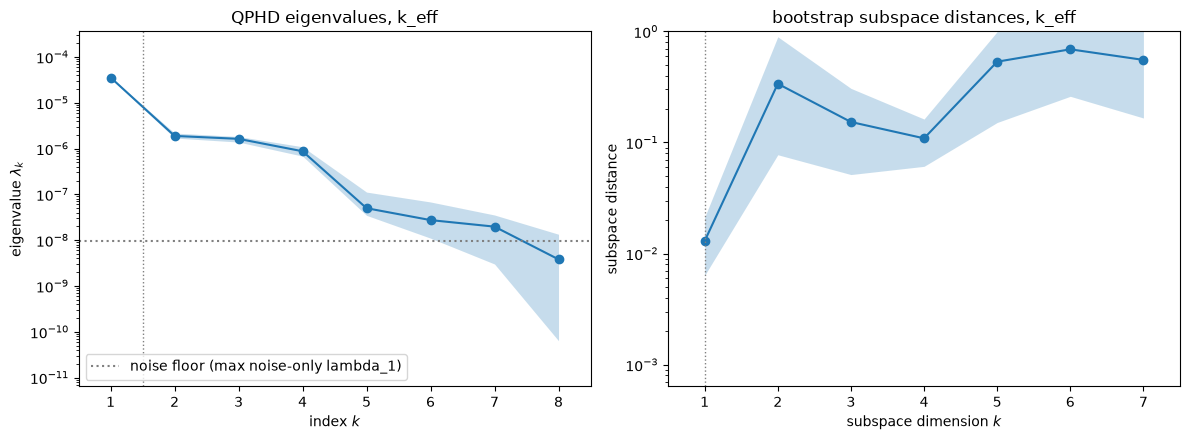

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_eigenvalues(sub_k, ax=axes[0])
axes[0].axhline(floor_k[:, 0].max(), color='0.5', ls=':', label='noise floor (max noise-only lambda_1)'); axes[0].legend(loc='lower left')
ac.plotting.plot_subspace_errors(sub_k, ax=axes[1])
axes[0].set_title('QPHD eigenvalues, k_eff'); axes[1].set_title('bootstrap subspace distances, k_eff')
fig.tight_layout(); plt.close(fig)
dist_k = sub_k.bootstrap_distances.mean(0)
print('mean bootstrap subspace distance, n = 1..7:', np.array2string(dist_k, precision=3))
fig

The one-dimensional subspace is very stable (mean distance 0.013), and so is the four-dimensional one (0.109); the two- and three-dimensional ones are not (0.337, 0.153), because $\lambda_2 \approx \lambda_3$ makes the split between $\mathbf w_2$ and $\mathbf w_3$ arbitrary.

**Eigenvectors** $\mathbf w_1$–$\mathbf w_4$ in the normalized insertion variables, with 95 % bootstrap intervals.

w1: -0.379 -0.315 -0.327 -0.383 -0.384 -0.325 -0.321 -0.385
w2: +0.298 +0.181 -0.382 -0.349 -0.320 -0.318 +0.484 +0.415
w3: -0.358 -0.340 -0.394 -0.282 +0.404 +0.502 +0.254 +0.205
w4: +0.428 +0.460 -0.347 -0.348 +0.186 +0.312 -0.396 -0.275
w1 on drums 1,4,5,8: [-0.379 -0.383 -0.384 -0.385]; on drums 2,3,6,7: [-0.315 -0.327 -0.325 -0.321]; ratio of means 1.189
quadrant signs of w2, w3, w4 (rows Q1..Q4):
 [[ 1 -1  1]
 [-1 -1 -1]
 [-1  1  1]
 [ 1  1 -1]]


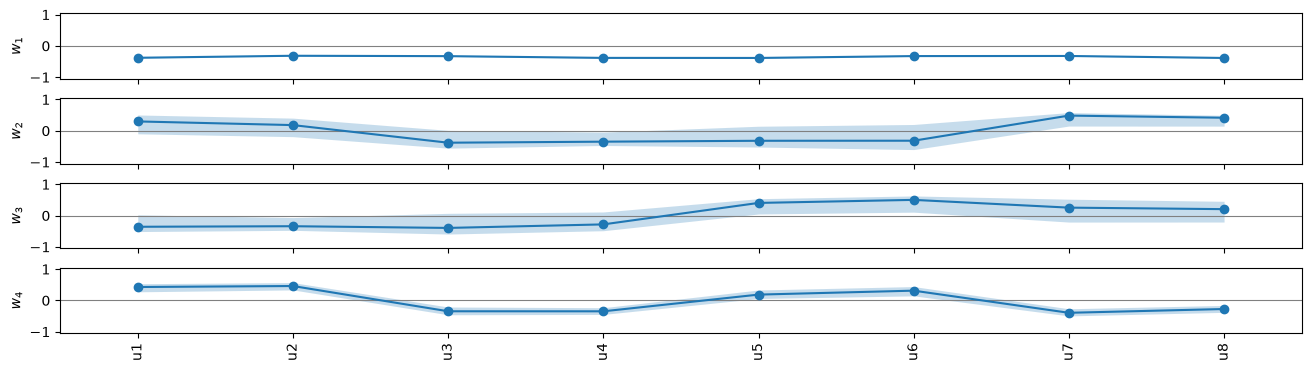

In [11]:
fig, axes = ac.plotting.plot_eigenvectors(sub_k, indices=[0, 1, 2, 3], labels=labels, interval='percentile', figsize=(13, 3.6))
plt.close(fig)
w_lo, w_hi = np.percentile(sub_k.bootstrap_eigenvectors, [2.5, 97.5], axis=0)
for i in range(4):
    print(f'w{i + 1}:', ' '.join(f'{sub_k.W[j, i]:+.3f}' for j in range(m)))
A_, B_ = [0, 3, 4, 7], [1, 2, 5, 6]
print(f'w1 on drums 1,4,5,8: {np.array2string(sub_k.W[A_, 0], precision=3)}; on drums 2,3,6,7: {np.array2string(sub_k.W[B_, 0], precision=3)}; '
      f'ratio of means {sub_k.W[A_, 0].mean() / sub_k.W[B_, 0].mean():.3f}')
signs = np.sign(sub_k.W[::2, 1:4] + sub_k.W[1::2, 1:4])   # sign per quadrant (sum of its two drums)
print('quadrant signs of w2, w3, w4 (rows Q1..Q4):\n', signs.astype(int))
fig

$\mathbf w_1$ is a nearly uniform weighting of all eight drums, negative because inserting any absorber lowers $k_\mathrm{eff}$: $-0.379$ to $-0.385$ on the side drums 1, 4, 5, 8 and $-0.315$ to $-0.327$ on drums 2, 3, 6, 7, equal within each symmetry orbit as the symmetry requires, with the side drums worth 1.189 times as much. The next three directions are the three ways of loading the core unevenly, one per non-trivial symmetry class: $\mathbf w_2$ has one sign on quadrants 1 and 4 and the other on 2 and 3 (left against right), $\mathbf w_3$ quadrants 1, 2 against 3, 4 (top against bottom), and $\mathbf w_4$ quadrants 1, 3 against 2, 4 (diagonal). Left–right and top–bottom have nearly equal eigenvalues ($\lambda_2/\lambda_3 = 1.16$), as a core that is almost square-symmetric would give.

**Sufficient summary plots.** Left: $k_\mathrm{eff}$ against $y_1$. Then the residual of a quadratic in $y_1$ (in pcm) against $y_2$, $y_3$ and $y_4$, each with a fitted parabola.

corr(y1, k_eff) = 0.9741; y1 range [-2.59, 2.47]
1-D quadratic: residual sd 131.8 pcm; Serpent sd 24.1 pcm
  corr(residual, y2^2) = +0.490
  corr(residual, y3^2) = +0.445
  corr(residual, y4^2) = +0.269


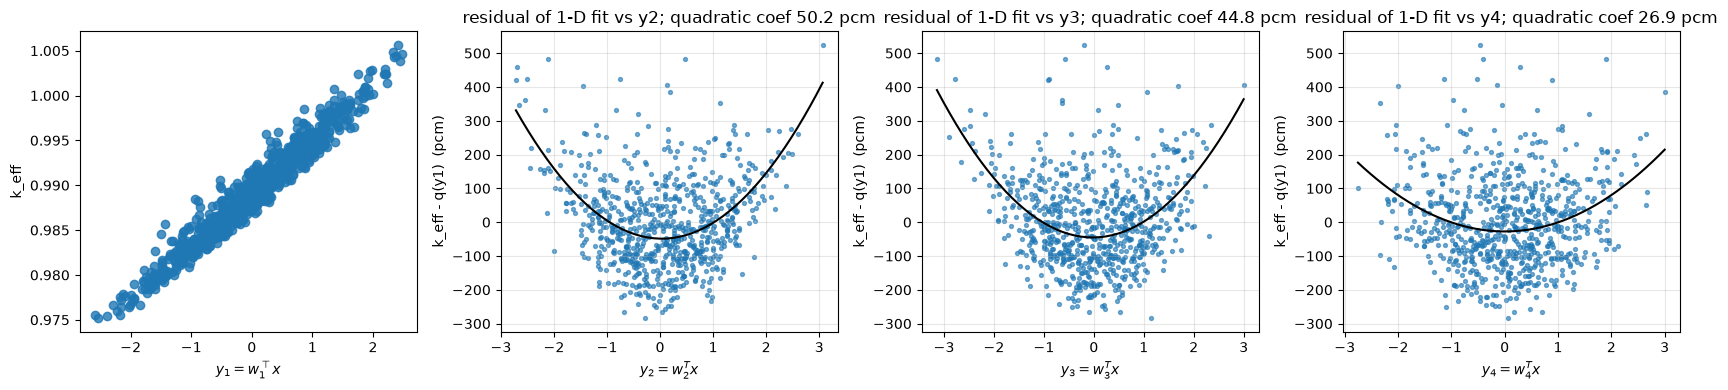

In [12]:
Z = space.to_normalized(U)                       # normalized inputs, x = u / sqrt(0.5)
Yk = Z @ sub_k.W
q1 = ac.fit_surrogate(X=U, f=k, space=space, subspace=ac.with_dimension(sub_k, 1), kind='poly', degree=2)
res1 = q1.residuals
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
ac.plotting.plot_sufficient_summary(ac.with_dimension(sub_k, 1), X=U, f=k, dims=1, qoi_label='k_eff', ax=axes[0])
for j in (1, 2, 3):
    axes[j].scatter(Yk[:, j], res1 * 1e5, s=8, alpha=0.6)
    c = np.polyfit(Yk[:, j], res1, 2); g = np.linspace(Yk[:, j].min(), Yk[:, j].max(), 50)
    axes[j].plot(g, np.polyval(c, g) * 1e5, 'k-')
    axes[j].set_xlabel(f'$y_{j + 1} = w_{j + 1}^T x$'); axes[j].set_ylabel('k_eff - q(y1)  (pcm)'); axes[j].grid(alpha=0.3)
    axes[j].set_title(f'residual of 1-D fit vs y{j + 1}; quadratic coef {c[0] * 1e5:.1f} pcm')
fig.tight_layout(); plt.close(fig)
print(f'corr(y1, k_eff) = {np.corrcoef(Yk[:, 0], k)[0, 1]:.4f}; y1 range [{Yk[:, 0].min():.2f}, {Yk[:, 0].max():.2f}]')
print(f'1-D quadratic: residual sd {res1.std() * 1e5:.1f} pcm; Serpent sd {np.mean(k_rsd * k) * 1e5:.1f} pcm')
for j in (1, 2, 3):
    print(f'  corr(residual, y{j + 1}^2) = {np.corrcoef(res1, Yk[:, j]**2)[0, 1]:+.3f}')
fig

$k_\mathrm{eff}$ falls almost linearly with $y_1$, i.e. with the weighted total insertion of the eight drums (correlation 0.9741). The residual of the one-variable fit (sd 131.8 pcm, against a Serpent sd of 24.1 pcm) is not noise: it grows with the square of the uneven-loading variables (correlations of the residual with $y_2^2$, $y_3^2$, $y_4^2$: +0.490, +0.445, +0.269), so for the same total insertion, a lopsided drum configuration has a higher $k_\mathrm{eff}$. The likely mechanism is flux shifting away from the inserted side, which lowers the worth of the inserted drums (the interaction effects the paper's hybrid drum-worth model captures with a statistical component, Sect. 2.2). This is why $\lambda_2$–$\lambda_4$ stand above the rest: $k_\mathrm{eff}$ is, to second order, a function of the four variables $y_1, \dots, y_4$.

### Estimate the subspace: quadrant power $P_1$

The same estimator for the four flux fractions; $P_1$ is reported in detail.

In [13]:
subs_P = [qphd(P[:, q]) for q in range(4)]
sub_P = subs_P[0]
lamP = sub_P.eigenvalues
lamP_lo, lamP_hi = ac.bootstrap_interval(sub_P.bootstrap_eigenvalues)
_, _, n_evg_P = ac.dimension_criterion(sub_P, rule='evg')
print('P1 eigenvalues and 95% bootstrap intervals:')
for i in range(m):
    print(f'  lambda_{i + 1} = {lamP[i]:.3e}  [{lamP_lo[i]:.3e}, {lamP_hi[i]:.3e}]' + (f'   lambda_{i + 1}/lambda_{i + 2} = {lamP[i] / lamP[i + 1]:.2f}' if i < m - 1 else ''))
r1P = sub_P.bootstrap_eigenvalues[:, 0] / sub_P.bootstrap_eigenvalues[:, 1]
print(f'lambda_1/lambda_2 = {lamP[0] / lamP[1]:.1f} (bootstrap 95% [{np.percentile(r1P, 2.5):.1f}, {np.percentile(r1P, 97.5):.1f}]); eigenvalue-gap rule: n = {n_evg_P}')
print(f'P1: noise sd {sd_noise_P1:.2e}; noise-only lambda_1 mean {floor_P[:, 0].mean():.2e}, max {floor_P[:, 0].max():.2e}; '
      f'eigenvalues above that max: {np.sum(lamP > floor_P[:, 0].max())} of {m}; lambda_1 / max = {lamP[0] / floor_P[:, 0].max():.0f}')
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    ols_P = ac.active_subspace(space=space, X=U, f=P[:, 0], estimator='ols', n=1)
print(f'global linear fit (OLS) direction: |w_OLS . w1| = {abs(ols_P.W[:, 0] @ sub_P.W[:, 0]):.4f}')

# Sensitivity to the declared input distribution (QPHD's C = g g^T + H Sigma H uses only its mean and covariance)
space_unif = ac.Uniform(-np.ones(m), np.ones(m), names=labels)          # as if u ~ U[-1, 1]: variance 1/3 instead of 1/2
def qphd_C(x, f, Sigma):
    """Plain-numpy QPHD in coordinates x with input covariance Sigma: least-squares quadratic, C = g g^T + H Sigma H."""
    i, j = np.triu_indices(m)
    c, *_ = np.linalg.lstsq(np.column_stack([np.ones(len(x)), x, x[:, i] * x[:, j]]), f, rcond=None)
    g, H = c[1:m + 1], np.zeros((m, m)); H[i, j] += c[m + 1:]; H = H + H.T
    lam_, W_ = np.linalg.eigh(np.outer(g, g) + H @ Sigma @ H)
    return lam_[::-1], W_[:, ::-1]
print(f"\n{'QoI':6s} {'Gaussian(0, 0.5 I)':>19s} {'numpy, Sigma = I':>17s} {'numpy, empirical Sigma':>23s} {'declared U[-1, 1]':>18s}   |w1 . w1'| (empirical, uniform)")
for name, s0, f in (('k_eff', sub_k, k), ('P1', sub_P, P[:, 0])):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')                  # ValidityWarning: QPHD on a uniform space
        su = ac.active_subspace(space=space_unif, X=U, f=f, estimator='qphd')
    lI, _ = qphd_C(Z, f, np.eye(m)); lE, WE = qphd_C(Z, f, np.cov(Z.T))
    print(f'{name:6s} {s0.eigenvalues[0] / s0.eigenvalues[1]:19.2f} {lI[0] / lI[1]:17.2f} {lE[0] / lE[1]:23.2f} {su.eigenvalues[0] / su.eigenvalues[1]:18.2f}'
          f'   {abs(WE[:, 0] @ s0.W[:, 0]):.5f}, {abs(su.W[:, 0] @ s0.W[:, 0]):.5f}')

P1 eigenvalues and 95% bootstrap intervals:
  lambda_1 = 1.700e-05  [1.646e-05, 1.760e-05]   lambda_1/lambda_2 = 35.70
  lambda_2 = 4.763e-07  [3.736e-07, 6.321e-07]   lambda_2/lambda_3 = 3.05
  lambda_3 = 1.561e-07  [1.144e-07, 3.120e-07]   lambda_3/lambda_4 = 1.43
  lambda_4 = 1.089e-07  [6.911e-08, 1.796e-07]   lambda_4/lambda_5 = 1.91
  lambda_5 = 5.694e-08  [2.578e-08, 1.057e-07]   lambda_5/lambda_6 = 17.42
  lambda_6 = 3.269e-09  [4.705e-09, 3.804e-08]   lambda_6/lambda_7 = 2.01
  lambda_7 = 1.624e-09  [9.308e-10, 1.745e-08]   lambda_7/lambda_8 = 11.43
  lambda_8 = 1.420e-10  [5.883e-11, 6.098e-09]
lambda_1/lambda_2 = 35.7 (bootstrap 95% [27.2, 45.2]); eigenvalue-gap rule: n = 1
P1: noise sd 3.17e-04; noise-only lambda_1 mean 7.57e-09, max 1.39e-08; eigenvalues above that max: 5 of 8; lambda_1 / max = 1219
global linear fit (OLS) direction: |w_OLS . w1| = 0.9997

QoI     Gaussian(0, 0.5 I)  numpy, Sigma = I  numpy, empirical Sigma  declared U[-1, 1]   |w1 . w1'| (empirical, unifo

$P_1$ has one dominant direction, $\lambda_1/\lambda_2 = 35.7$ (bootstrap 95 % interval $[27.2, 45.2]$; $n = 1$ by the gap rule), $\lambda_1$ is 1219 times the noise floor computed from the stored flux uncertainties (noise sd of $P_1$: 3.17e-4), and five of the eight eigenvalues exceed that floor. The noise sd assumes independent tally errors of one standard deviation and is an upper bound (see the surrogate section), so this floor is conservative. The global linear direction agrees ($|\mathbf w_{\mathrm{OLS}}\cdot\mathbf w_1| = 0.9997$).

**Sensitivity to the declared input distribution.** The last table recomputes $\lambda_1/\lambda_2$ with plain numpy: with $\boldsymbol\Sigma = \mathbf I$ in the normalized inputs it reproduces the library (18.83 for $k_\mathrm{eff}$, 35.70 for $P_1$); with the sample covariance of the 751 runs instead of the arcsine law's it gives 19.34 and 36.32. Declaring $u$ uniform on $[-1, 1]$ would give 28.16 and 52.34, because the uniform variance (1/3) is smaller than the actual one (1/2) and so shrinks the curvature term. The first directions agree in all cases ($|\mathbf w_1\cdot\mathbf w_1'| \ge 0.99997$), so the declared distribution affects the size of the gaps, not the subspace; the gaps quoted in this notebook are those of the sampling distribution.

**Eigenvalues, subspace errors and sufficient summary plot** for $P_1$.

mean bootstrap subspace distance, n = 1..7: [0.021 0.158 0.447 0.413 0.333 0.759 0.765]
w1 (P1): -0.613 -0.601 +0.090 +0.171 +0.320 +0.296 +0.177 +0.073 | corr(y1, P1) = 0.9701
95% intervals of w1: [-0.625,-0.599] [-0.615,-0.587] [+0.074,+0.108] [+0.155,+0.185] [+0.306,+0.333] [+0.280,+0.313] [+0.161,+0.192] [+0.059,+0.088]


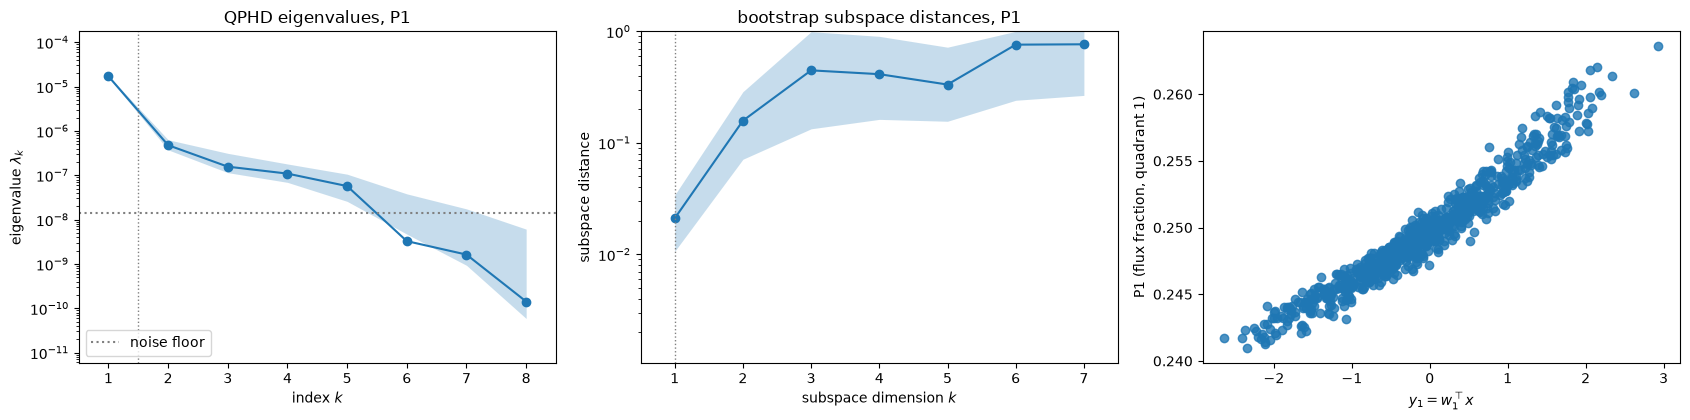

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
ac.plotting.plot_eigenvalues(sub_P, ax=axes[0])
axes[0].axhline(floor_P[:, 0].max(), color='0.5', ls=':', label='noise floor'); axes[0].legend(loc='lower left')
ac.plotting.plot_subspace_errors(sub_P, ax=axes[1])
ac.plotting.plot_sufficient_summary(ac.with_dimension(sub_P, 1), X=U, f=P[:, 0], dims=1, qoi_label='P1 (flux fraction, quadrant 1)', ax=axes[2])
axes[0].set_title('QPHD eigenvalues, P1'); axes[1].set_title('bootstrap subspace distances, P1')
fig.tight_layout(); plt.close(fig)
dist_P = sub_P.bootstrap_distances.mean(0)
YP = Z @ sub_P.W
print('mean bootstrap subspace distance, n = 1..7:', np.array2string(dist_P, precision=3))
print('w1 (P1):', ' '.join(f'{v:+.3f}' for v in sub_P.W[:, 0]), f'| corr(y1, P1) = {np.corrcoef(YP[:, 0], P[:, 0])[0, 1]:.4f}')
wlo, whi = np.percentile(sub_P.bootstrap_eigenvectors[:, :, 0], [2.5, 97.5], axis=0)
print('95% intervals of w1:', ' '.join(f'[{a:+.3f},{b:+.3f}]' for a, b in zip(wlo, whi)))
fig

The first direction is well determined (mean subspace distance 0.021; every component's 95 % interval excludes zero). $P_1$ rises along $\mathbf w_1$ (correlation 0.9701 with $y_1$), which weights the two drums of quadrant 1 at $-0.613$ and $-0.601$ (inserting them lowers the quadrant's share), the opposite quadrant 3's drums at $+0.320$ and $+0.296$ (inserting them pushes power into quadrant 1), and the four drums of the neighbouring quadrants in between: $+0.171$ and $+0.177$ for drums 4 and 7, which sit far from quadrant 1, and only $+0.090$ and $+0.073$ for drums 3 and 8, the neighbouring quadrants' drums nearest quadrant 1, which depress it almost as much as their own quadrant. The scatter about the trend (correlation 0.97, not 1) is the second direction and the turning-direction ($\sin\theta$) effects found above.

**Rotated subspaces across quadrants.** The first eigenvectors of $P_1, \dots, P_4$, and the dot products between each and the image of $\mathbf w_1(P_1)$ under the symmetry that carries quadrant 1 to that quadrant.

P1: lambda1/lambda2 = 35.7; w1 = -0.613 -0.601 +0.090 +0.171 +0.320 +0.296 +0.177 +0.073
P2: lambda1/lambda2 = 30.9; w1 = +0.172 +0.095 -0.613 -0.600 +0.090 +0.171 +0.297 +0.317
P3: lambda1/lambda2 = 37.1; w1 = +0.310 +0.282 +0.175 +0.090 -0.608 -0.609 +0.103 +0.186
P4: lambda1/lambda2 = 41.9; w1 = +0.091 +0.173 +0.301 +0.316 +0.190 +0.111 -0.604 -0.598
h: Q1 -> Q2: |w1(P2) . (w1(P1) permuted)| = 0.9997
r: Q1 -> Q3: |w1(P3) . (w1(P1) permuted)| = 0.9995
v: Q1 -> Q4: |w1(P4) . (w1(P1) permuted)| = 0.9993


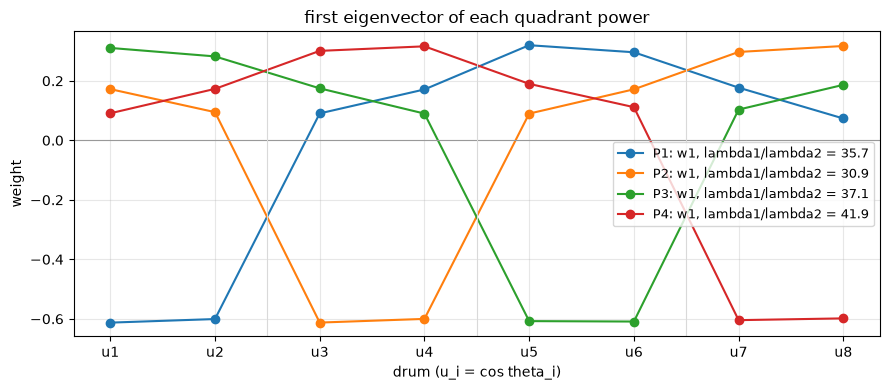

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
x_ = np.arange(1, m + 1)
for q in range(4):
    ax.plot(x_, subs_P[q].W[:, 0], 'o-', label=f'P{q + 1}: w1, lambda1/lambda2 = {subs_P[q].eigenvalues[0] / subs_P[q].eigenvalues[1]:.1f}')
ax.set_xticks(x_, labels); ax.axhline(0, color='0.6', lw=0.8); ax.set_xlabel('drum (u_i = cos theta_i)'); ax.set_ylabel('weight')
for b in (2.5, 4.5, 6.5): ax.axvline(b, color='0.85', lw=0.8)
ax.legend(fontsize=9); ax.set_title('first eigenvector of each quadrant power'); ax.grid(alpha=0.3)
fig.tight_layout(); plt.close(fig)
for q in range(4):
    print(f'P{q + 1}: lambda1/lambda2 = {subs_P[q].eigenvalues[0] / subs_P[q].eigenvalues[1]:.1f}; w1 =', ' '.join(f'{v:+.3f}' for v in subs_P[q].W[:, 0]))
for g in 'hrv':
    q = QMAP[g][0]
    w_img = np.empty(m); w_img[DRUM[g]] = sub_P.W[:, 0]           # w1(P1) carried by the symmetry
    print(f'{g}: Q1 -> Q{q + 1}: |w1(P{q + 1}) . (w1(P1) permuted)| = {abs(w_img @ subs_P[q].W[:, 0]):.4f}')
fig

Each quadrant's direction is the quadrant-1 direction carried around the core: its own two drums at about $-0.61$, the opposite quadrant's at about $+0.3$, and the near drums of the neighbouring quadrants smallest. The permuted $\mathbf w_1(P_1)$ matches $\mathbf w_1(P_2)$, $\mathbf w_1(P_3)$ and $\mathbf w_1(P_4)$ with $|\mathbf w\cdot\mathbf w'| = 0.9997$, 0.9995 and 0.9993, computed from separate fits, so the estimated subspaces respect the core's symmetry to within their bootstrap error. The four leading gaps are 35.7, 30.9, 37.1 and 41.9.

### Symmetry augmentation (an analysis step, as in the paper)

The paper trains on 3004 rows, the 751 runs and their three images. In $u$ the images are permutations, so augmentation is exact here; the cell recomputes both subspaces from the 3004 rows (no bootstrap, since the rows are not independent).

In [16]:
# Symmetry augmentation as in the paper (751 -> 3004 rows). In u = cos(theta) every image is a permutation of the drums.
Ua, ka, Pa = [U], [k], [P]
for g in 'hrv':
    u2 = np.empty_like(U); u2[:, DRUM[g]] = U
    p2 = np.empty_like(P); p2[:, QMAP[g]] = P
    Ua.append(u2); ka.append(k); Pa.append(p2)
Ua, ka, Pa = np.vstack(Ua), np.concatenate(ka), np.vstack(Pa)
aug_k = qphd(ka, X=Ua, nboot=0)
aug_P = qphd(Pa[:, 0], X=Ua, nboot=0)
print('augmented rows:', Ua.shape[0])
for name, s0, s1 in (('k_eff', sub_k, aug_k), ('P1', sub_P, aug_P)):
    print(f'{name}: lambda1/lambda2 raw {s0.eigenvalues[0] / s0.eigenvalues[1]:.1f}, augmented {s1.eigenvalues[0] / s1.eigenvalues[1]:.1f}; '
          f'|w1_raw . w1_aug| = {abs(s0.W[:, 0] @ s1.W[:, 0]):.4f}; w1_aug =', np.array2string(s1.W[:, 0], precision=3))
print(f'k_eff: largest |w1_raw - w1_aug| component difference {np.abs(sub_k.W[:, 0] - aug_k.W[:, 0]).max():.4f}')
print('k_eff augmented eigenvalue ratios:', np.array2string(aug_k.eigenvalues[:-1] / aug_k.eigenvalues[1:], precision=2))

augmented rows: 3004
k_eff: lambda1/lambda2 raw 18.8, augmented 19.5; |w1_raw . w1_aug| = 0.9999; w1_aug = [-0.382 -0.322 -0.322 -0.382 -0.382 -0.322 -0.322 -0.382]
P1: lambda1/lambda2 raw 35.7, augmented 37.4; |w1_raw . w1_aug| = 0.9998; w1_aug = [-0.605 -0.606  0.101  0.181  0.316  0.293  0.173  0.085]
k_eff: largest |w1_raw - w1_aug| component difference 0.0076
k_eff augmented eigenvalue ratios: [19.51  1.16  1.76 21.16  1.84  1.08  4.14]


Augmentation changes little: $|\mathbf w_1^{\mathrm{raw}}\cdot\mathbf w_1^{\mathrm{aug}}| = 0.9999$ for $k_\mathrm{eff}$ and 0.9998 for $P_1$, with gaps of 19.5 and 37.4 instead of 18.8 and 35.7. For $k_\mathrm{eff}$ the augmented direction is exactly symmetric (0.382 on the side drums, 0.322 on the others), which the raw estimate matches to within 0.0076 per component. The augmented $k_\mathrm{eff}$ spectrum shows the same 1 + 3 structure (ratios 19.51, 1.16, 1.76, 21.16).

### Surrogates on the active variables

Polynomials of degree 1–3 in one, two or four active variables, scored by leave-one-out $R^2$ (the subspace is held at the full-sample estimate, so the values are slightly optimistic). For comparison with the paper's Table 2, the leave-one-out RMSE and MAE of $P_1$ are computed for the two-variable quadratic, for a full quadratic in all eight $u_i$, and for a linear regression on the angles.

In [17]:
def loo_errors(Y, f, deg):
    """Leave-one-out residuals of a least-squares polynomial of total degree deg in the columns of Y (hat matrix)."""
    cols = [np.ones(len(f))]
    from itertools import combinations_with_replacement
    for d in range(1, deg + 1):
        cols += [np.prod(Y[:, list(c)], axis=1) for c in combinations_with_replacement(range(Y.shape[1]), d)]
    B = np.column_stack(cols); Q, _ = np.linalg.qr(B)
    c, *_ = np.linalg.lstsq(B, f, rcond=None)
    return (f - B @ c) / (1 - np.sum(Q**2, axis=1))
loo = {}
for name, s, f, ns in (('k_eff', sub_k, k, (1, 2, 4)), ('P1', sub_P, P[:, 0], (1, 2))):
    for n_ in ns:
        row = []
        for deg in (1, 2, 3):
            srg = ac.fit_surrogate(X=U, f=f, space=space, subspace=ac.with_dimension(s, n_), kind='poly', degree=deg)
            loo[(name, n_, deg)] = srg.loo_r_squared; row.append(srg.loo_r_squared)
        print(f'{name}, {n_}-D active variables, LOO R^2 for degree 1, 2, 3:', '  '.join(f'{v:.4f}' for v in row))
e_full = loo_errors(U, P[:, 0], 2); e_as2 = loo_errors(YP[:, :2], P[:, 0], 2); e_lin = loo_errors(theta, P[:, 0], 1)
e_k1 = loo_errors(Yk[:, :1], k, 2); e_k4 = loo_errors(Yk[:, :4], k, 2)
print(f'\nP1, LOO RMSE / MAE: 2-D quadratic {np.sqrt(np.mean(e_as2**2)):.2e} / {np.mean(np.abs(e_as2)):.2e}; '
      f'full quadratic in u (45 terms) {np.sqrt(np.mean(e_full**2)):.2e} / {np.mean(np.abs(e_full)):.2e}; '
      f'linear in theta {np.sqrt(np.mean(e_lin**2)):.2e} / {np.mean(np.abs(e_lin)):.2e} (LOO R^2 {1 - np.sum(e_lin**2) / np.sum((P[:, 0] - P[:, 0].mean())**2):.3f})')
print(f'k_eff, LOO RMSE: 1-D quadratic {np.sqrt(np.mean(e_k1**2)) * 1e5:.1f} pcm, 4-D quadratic {np.sqrt(np.mean(e_k4**2)) * 1e5:.1f} pcm '
      f'(Serpent sd {np.mean(k_rsd * k) * 1e5:.1f} pcm)')

# Is the stored noise level consistent with the data? Best fit (145-term Fourier basis) against pure noise, with leverage
sdP1_run = np.sqrt(((1 - P[:, 0]) * P[:, 0] * flux_rsd[:, 0])**2 + P[:, 0]**2 * np.sum((P[:, 1:] * flux_rsd[:, 1:])**2, axis=1))
for name, sd_run in (('P1', sdP1_run), ('k_eff', k_rsd * k)):
    exp_loo = np.sqrt(np.mean(sd_run**2 / (1 - h_full)))     # expected LOO RMSE if the fit were exact and the noise independent, 1 sd
    print(f'{name}: best-fit LOO RMSE {loo_rmse_full[name]:.2e}; expected from noise alone {exp_loo:.2e} (rsd = 1 sd, independent tallies), '
          f'{exp_loo / 2:.2e} (rsd = 2 sd); rms of the per-run noise sd (1 sd, independent) {np.sqrt(np.mean(sd_run**2)):.2e}')
res_flux = np.array([flux[:, q] - FULL @ np.linalg.lstsq(FULL, flux[:, q], rcond=None)[0] for q in range(4)])
Rf = np.corrcoef(res_flux)
print(f'correlation of the four quadrant flux residuals (145-term fit): {Rf[np.triu_indices(4, 1)].min():.2f} .. {Rf[np.triu_indices(4, 1)].max():.2f}')
print(f'P1 2-D quadratic LOO RMSE / upper bound on the noise sd (best-fit LOO RMSE): {np.sqrt(np.mean(e_as2**2)) / loo_rmse_full["P1"]:.1f}')
print(f'\nnotebook run time: {time.perf_counter() - t_start:.1f} s')

k_eff, 1-D active variables, LOO R^2 for degree 1, 2, 3: 0.9486  0.9490  0.9490
k_eff, 2-D active variables, LOO R^2 for degree 1, 2, 3: 0.9484  0.9611  0.9608
k_eff, 4-D active variables, LOO R^2 for degree 1, 2, 3: 0.9481  0.9837  0.9840
P1, 1-D active variables, LOO R^2 for degree 1, 2, 3: 0.9407  0.9507  0.9505
P1, 2-D active variables, LOO R^2 for degree 1, 2, 3: 0.9407  0.9616  0.9618

P1, LOO RMSE / MAE: 2-D quadratic 8.00e-04 / 6.33e-04; full quadratic in u (45 terms) 7.73e-04 / 6.09e-04; linear in theta 4.11e-03 / 3.24e-03 (LOO R^2 -0.015)
k_eff, LOO RMSE: 1-D quadratic 132.2 pcm, 4-D quadratic 74.8 pcm (Serpent sd 24.1 pcm)
P1: best-fit LOO RMSE 2.77e-04; expected from noise alone 3.51e-04 (rsd = 1 sd, independent tallies), 1.76e-04 (rsd = 2 sd); rms of the per-run noise sd (1 sd, independent) 3.15e-04
k_eff: best-fit LOO RMSE 4.15e-04; expected from noise alone 2.68e-04 (rsd = 1 sd, independent tallies), 1.34e-04 (rsd = 2 sd); rms of the per-run noise sd (1 sd, independent) 

correlation of the four quadrant flux residuals (145-term fit): 0.98 .. 0.99
P1 2-D quadratic LOO RMSE / upper bound on the noise sd (best-fit LOO RMSE): 2.9

notebook run time: 6.6 s


For $k_\mathrm{eff}$, one active variable gives LOO $R^2 = 0.9490$ (degree 2), two give 0.9611 and four 0.9837 (degree 2), the last as good as a full 45-term quadratic in $u$ (in-sample 0.9854); the four-variable quadratic's LOO RMSE of 74.8 pcm is still three times the Serpent noise (24.1 pcm), the remainder being the turning-direction and higher-harmonic effects. For $P_1$, one active variable gives 0.9507 and two give 0.9616. The two-variable quadratic's LOO RMSE and MAE, 8.00e-4 and 6.33e-4, are close to those of a full quadratic in $u$ (7.73e-4, 6.09e-4) and to the paper's deep network (test 6.05e-4 and 4.62e-4, Table 2). A linear regression on the angles has LOO $R^2 = -0.015$, MAE 3.24e-3 and RMSE 4.11e-3, close to the paper's linear regression (test $R^2$ 0.00, MAE 3.41e-3, RMSE 4.23e-3, Table 2, p. 14): not because the problem is hard, but because the angles are the wrong coordinates.

**The noise level of $P_1$ is an upper bound.** The noise used above (sd 3.17e-4 for $P_1$) treats the stored relative uncertainties as one standard deviation and the four quadrant tallies as independent. The 145-term Fourier fit of $P_1$ reaches a LOO RMSE of 2.77e-4, below the 3.51e-4 that noise of that size alone would give (with leverage) even for an exact fit. The quadrant flux residuals of that fit are correlated at 0.98–0.99, so a common-mode error cancels in the ratio $P_q$; either the tally errors are correlated, or the stored uncertainties are two standard deviations, as the note in the authors' repository suggests (expected LOO RMSE 1.76e-4). The noise floors above are therefore conservative, and the two-variable quadratic's LOO RMSE is at least 2.9 times the actual noise of $P_1$ (8.00e-4 against the bound 2.77e-4). For $k_\mathrm{eff}$ the same test is inconclusive: the 145-term fit's LOO RMSE, 4.15e-4, is above the 2.68e-4 expected from noise alone, so model error remains even in that basis.

### Comparison with the paper

The paper reports no active subspace; the comparison is with its description of the data and its Table 2. Its metrics are test-set values on the 3004-row augmented set, averaged over the four quadrants and computed on scaled outputs; the notebook's are leave-one-out values on the 751 raw runs for $P_1$, so they are comparable in size only.

| quantity | paper | notebook |
|---|---|---|
| simulator | Serpent, continuous-energy Monte Carlo (Sect. 2.3, p. 7) | stored Serpent outputs, not rerun |
| runs | "about 3000 samples after using reactor symmetries" (p. 7); 2404 training + 600 test (Table 1) | 751 runs (run numbers 0–818, 68 absent); ×4 images = 3004 |
| drum angles | independent uniform on $[-180°, 180°]$ (p. 7) | local angles span the circle; KS p ≥ 0.32; largest correlation 0.069 |
| quadrant power | flux in each quadrant, relative (Eq. 1, p. 7; p. 14) | $P_q = \phi_q/\sum_j\phi_j$ from the flux tallies |
| QPTR limit | 1.02 (p. 7) | 388 of 751 runs above 1.02 (QPTR 1.0021–1.0611) |
| Monte Carlo uncertainty | not reported for the data; "negligible" for QPTR at the optima (p. 25) | $k_\mathrm{eff}$: 24.1 pcm; flux tallies 0.100–0.214 %; $P_1$: at most 3.17e-4 (best-fit LOO RMSE 2.77e-4) |
| linear regression, test MAE / RMSE / $R^2$ | 3.41e-3 / 4.23e-3 / 0.00 (Table 2, p. 14) | linear in angles, LOO: 3.24e-3 / 4.11e-3 / −0.015; linear in $\cos\theta$, in-sample $R^2$ 0.9417 |
| effect of the turning direction (odd part) | not reported | 1.2 % of the variance of $k_\mathrm{eff}$, about 3 % of $P_1$–$P_4$ |
| DNN test MAE / RMSE / $R^2$ | 4.62e-4 / 6.05e-4 / 0.98 (Table 2) | 2-variable quadratic in active variables, LOO: 6.33e-4 / 8.00e-4 / 0.9616 |
| random forest, decision tree test $R^2$ | 0.75, 0.29 (Table 2) | not computed |
| active subspace of $k_\mathrm{eff}$ | not reported | $\lambda_1/\lambda_2 = 18.8$, $\lambda_4/\lambda_5 = 17.5$; LOO $R^2$ 0.9490 (1-D), 0.9837 (4-D) |
| active subspace of $P_1$ | not reported | $\lambda_1/\lambda_2 = 35.7$; LOO $R^2$ 0.9507 (1-D), 0.9616 (2-D) |
| verification at optima | QPTR 1.010 (Serpent) vs 1.011 (surrogate), $k_\mathrm{eff}$ error 74 ± 13 pcm (Sect. 4.5, p. 25) | not reproducible (no new runs) |

### References

[1] D. Price, M. I. Radaideh and B. Kochunas, "Multiobjective optimization of nuclear microreactor reactivity control system operation with swarm and evolutionary algorithms", *Nuclear Engineering and Design* 393:111776, 2022. [doi:10.1016/j.nucengdes.2022.111776](https://doi.org/10.1016/j.nucengdes.2022.111776). Data and code: [github.com/deanrp2/MicroControl](https://github.com/deanrp2/MicroControl) (the repository's only licence is MIT, which grants rights to "this software and associated documentation files" and does not mention data; the data file is hosted here with credit); a rounded copy of the data is in the pyMAISE benchmark data, [doi:10.5281/zenodo.20140559](https://doi.org/10.5281/zenodo.20140559) (CC BY 4.0).

[2] P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, Philadelphia, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

[3] P. G. Constantine, E. Dow and Q. Wang, "Active subspace methods in theory and practice: applications to kriging surfaces", *SIAM Journal on Scientific Computing* 36(4):A1500–A1524, 2014. [doi:10.1137/130916138](https://doi.org/10.1137/130916138).

[4] K.-C. Li, "On principal Hessian directions for data visualization and dimension reduction: another application of Stein's lemma", *Journal of the American Statistical Association* 87(420):1025–1039, 1992. [doi:10.1080/01621459.1992.10476258](https://doi.org/10.1080/01621459.1992.10476258).

[5] J. Leppänen, M. Pusa, T. Viitanen, V. Valtavirta and T. Kaltiaisenaho, "The Serpent Monte Carlo code: status, development and applications in 2013", *Annals of Nuclear Energy* 82:142–150, 2015. [doi:10.1016/j.anucene.2014.08.024](https://doi.org/10.1016/j.anucene.2014.08.024).

[6] P. A. Myers, N. Panczyk, S. Chidige, C. Craig, J. Cooper, V. Joynt and M. I. Radaideh, "pyMAISE: A Python platform for automatic machine learning and accelerated development for nuclear power applications", *Progress in Nuclear Energy* 180:105568, 2025. [doi:10.1016/j.pnucene.2024.105568](https://doi.org/10.1016/j.pnucene.2024.105568).

[R1]: https://doi.org/10.1016/j.nucengdes.2022.111776
[R2]: https://doi.org/10.1137/1.9781611973860
[R3]: https://doi.org/10.1137/130916138
[R4]: https://doi.org/10.1080/01621459.1992.10476258
[R5]: https://doi.org/10.1016/j.anucene.2014.08.024
[R6]: https://doi.org/10.1016/j.pnucene.2024.105568

### Acknowledgments

The paper acknowledges an Integrated University Program Graduate Fellowship and funding from the U.S. Department of Energy Office of Nuclear Energy's Nuclear Energy University Program under contract DE-NE0008887.